In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

In [3]:
df = pd.read_parquet("../data/processed/clean.parquet")

print(f"Transactions : {len(df):,}")
print(f"Unique invoices: {df['InvoiceNo'].nunique():,}")
print(f"Unique items: {df['StockCode'].nunique():,}")

Transactions : 776,579
Unique invoices: 36,594
Unique items: 4,620


In [4]:
top_300 = df.groupby("StockCode")["InvoiceNo"].nunique().nlargest(300).index.tolist()
desc_map = df.groupby("StockCode")["Description"].agg(lambda x: x.mode()[0] if not x.empty else "").to_dict()
df_top = df[df["StockCode"].isin(top_300)][["InvoiceNo", "StockCode"]].drop_duplicates()

basket = df_top.groupby("InvoiceNo")["StockCode"].apply(set)
n_baskets = len(basket)

print(f"Number of invoices that contains atleast 1 of top300 items: {n_baskets:,}")
print(f"Covered invoices percentage: {n_baskets / df.InvoiceNo.nunique() * 100:.1f}%")

Number of invoices that contains atleast 1 of top300 items: 33,081
Covered invoices percentage: 90.4%


In [5]:
item_counts = df_top["StockCode"].value_counts().to_dict()

pair_counts = Counter()
for items in basket:
    if len(items) > 1:
        for a, b in combinations(sorted(items), 2):
            pair_counts[(a, b)] += 1

print(f"Unique item pairs: {len(pair_counts):,}")

records = []
for (a, b), count_ab in pair_counts.items():
    supp_ab = count_ab / n_baskets
    supp_a = item_counts[a] / n_baskets
    supp_b = item_counts[b] / n_baskets
    lift = supp_ab / (supp_a * supp_b)
    conf_a_b = count_ab / item_counts[a]
    conf_b_a = count_ab / item_counts[b]
    
    records.append({
        "Item_A": a,
        "Name_A": desc_map.get(a, a),
        "Item_B": b,
        "Name_B": desc_map.get(b, b),
        "Common": count_ab,
        "Support": supp_ab,
        "Confidence_A_B": conf_a_b,
        "Confidence_B_A": conf_b_a,
        "Lift": lift
    })

rules = pd.DataFrame(records)
print(f"Pairs with Lift > 1: {(rules['Lift'] > 1).sum():,} from total {len(rules):,}")
print(f"Max Lift: {rules['Lift'].max():.2f}")

Unique item pairs: 44,834
Pairs with Lift > 1: 37,740 from total 44,834
Max Lift: 37.64


In [7]:
top_pairs = rules.sort_values("Lift", ascending=False).head(15)

show = top_pairs[["Name_A", "Name_B", "Common", "Confidence_A_B", "Confidence_B_A", "Lift"]].copy()
show.columns = ["Item A", "Item B", "Together (invoices)", "Conf (A->B)", "Conf (B->A)", "Lift"]
show

,Item A,Item B,Together (invoices),Conf (A->B),Conf (B->A),Lift
714,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,489,0.787440,0.706647,37.643482
1354,SET/10 PINK POLKADOT PARTY CANDLES,SET/10 BLUE SPOTTY PARTY CANDLES,480,0.649526,0.801336,35.871423
32936,FELTCRAFT PRINCESS CHARLOTTE DOLL,FELTCRAFT PRINCESS LOLA DOLL,379,0.610306,0.634841,33.818311
372,RED STRIPE CERAMIC DRAWER KNOB,BLUE STRIPE CERAMIC DRAWER KNOB,400,0.651466,0.625978,33.726354
30281,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,469,0.645117,0.706325,32.140230
20848,FELTCRAFT CUSHION BUTTERFLY,FELTCRAFT CUSHION RABBIT,445,0.655376,0.657312,32.024341
42755,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,463,0.729134,0.612434,31.905393
31762,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,635,0.671247,0.841060,29.411303
373,RED STRIPE CERAMIC DRAWER KNOB,WHITE SPOT RED CERAMIC DRAWER KNOB,340,0.553746,0.544000,29.309550
15119,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,437,0.690363,0.539506,28.194951


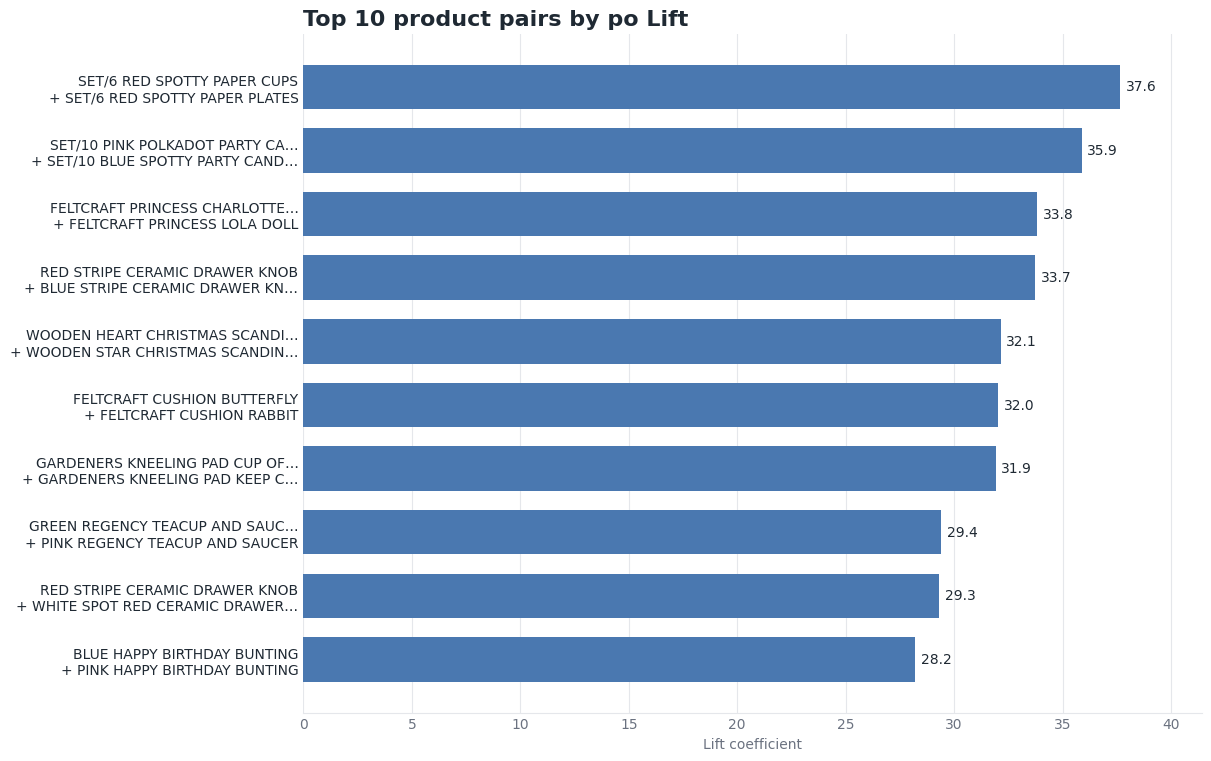

In [8]:
INK = "#1f2933"
MUTED = "#6b7280"
GRID = "#e5e7eb"
BASE = "#4a78b0"
ACCENT = "#e07a2f"


def shorten(text: str, n: int=30) -> str:
    return text if len(text) <= n else text[: n - 1].rstrip() + "…"

top_pairs = rules.sort_values("Lift", ascending=True).tail(10)
labels = [f"{shorten(a)}\n+ {shorten(b)}"
          for a, b in zip(top_pairs["Name_A"], top_pairs["Name_B"])]

fig, ax = plt.subplots(figsize=(12, 7.5), constrained_layout=True)

bars = ax.barh(labels, top_pairs["Lift"], color=BASE, height=0.7)
ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=10, color=INK)

ax.set_title(
    "Top 10 product pairs by po Lift",
    loc="left",
    fontsize=16, 
    fontweight="bold", 
    color=INK
)

ax.set_xlabel("Lift coefficient", color=MUTED)
ax.margins(x=0.1)

ax.tick_params(axis="x", colors=MUTED, length=0)
ax.tick_params(axis="y", labelcolor=INK, labelsize=10, length=0)
ax.set_axisbelow(True)

ax.xaxis.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
    
ax.spines["bottom"].set_color(GRID)

plt.show()

In [10]:
def recommend(item_code: str, top_n: int = 5) -> pd.DataFrame:
    code = str(item_code).strip().upper()
    
    part_a = rules[rules["Item_A"] == code].copy()
    part_a["Recommended_Code"] = part_a["Item_B"]
    part_a["Recommended_Name"] = part_a["Name_B"]
    part_a["Confidence"] = part_a["Confidence_A_B"]
    
    part_b = rules[rules["Item_B"] == code].copy()
    part_b["Recommended_Code"] = part_b["Item_A"]
    part_b["Recommended_Name"] = part_b["Name_A"]
    part_b["Confidence"] = part_b["Confidence_B_A"]
    
    merged = pd.concat([
        part_a[["Recommended_Code", "Recommended_Name", "Common", "Confidence", "Lift"]],
        part_b[["Recommended_Code", "Recommended_Name", "Common", "Confidence", "Lift"]]
    ])
    
    if merged.empty:
        return pd.DataFrame()
    
    result = merged.sort_values(by=["Lift", "Confidence"], ascending=False).head(top_n).reset_index(drop=True)
    
    query_name = desc_map.get(code, code)
    print(f"=== RECOMMENDATIONS FOR ITEM: {query_name} ({code}) ===")
    return result

test_code_1 = "22998"
recommendations_1 = recommend(test_code_1, top_n=5)
print(recommendations_1.round(3).to_string())

print("\n" + "="*70 + "\n")

if "22699" in desc_map:  
    recommendations_2 = recommend("22699", top_n=5)
    print(recommendations_2.round(3).to_string())

Empty DataFrame
Columns: []
Index: []


=== RECOMMENDATIONS FOR ITEM: ROSES REGENCY TEACUP AND SAUCER (22699) ===
  Recommended_Code                  Recommended_Name  Common  Confidence    Lift
0            22698    PINK REGENCY TEACUP AND SAUCER     605       0.565  24.774
1            22697   GREEN REGENCY TEACUP AND SAUCER     754       0.705  24.642
2            23245        SET OF 3 REGENCY CAKE TINS     133       0.124   5.727
3            22423          REGENCY CAKESTAND 3 TIER     588       0.550   5.481
4            22907  PACK OF 20 NAPKINS PANTRY DESIGN      89       0.083   4.076


In [11]:
rules.to_parquet("../data/processed/rules_recommendation.parquet", index=False)